# Chapter 25: Project: Air Quality and Clinic Visits

The programs from Chapter 25 of *Data Analysis with Python, Hands-On* by Aadhavan Muthurengan, in the book's order. Each code cell is one program; the same program is in this folder as a `.py` file, and its expected output is in the `.out` file with the same name.

Run the cells from top to bottom (**Run > Run All Cells**). The programs read the datasets from `../data/`, so keep this notebook in its chapter folder.

## Preparing the Data

`health_prepare.py`

In [1]:
import pandas as pd

air = pd.read_csv("../data/air_quality.csv", parse_dates=["date"])
visits = pd.read_csv("../data/clinic_visits.csv", parse_dates=["date"])

missing = air["pm25"].isna().groupby(air["city"]).sum()
print("missing PM2.5 readings:", missing.to_dict())

# Fill short sensor gaps (up to 3 days) from the neighboring days
air["pm25"] = air.groupby("city")["pm25"].transform(
    lambda s: s.interpolate(limit=3)
)
df = air.merge(visits, on=["date", "city"], validate="one_to_one")
print("rows:", len(df), "| still missing:", df["pm25"].isna().sum())

df["quarter"] = df["date"].dt.quarter
print(
    df.pivot_table(index="city", columns="quarter", values="pm25").round(1)
)

missing PM2.5 readings: {'Avonford': 9, 'Brightwater': 8, 'Cedarvale': 4}
rows: 1095 | still missing: 0
quarter         1     2     3     4
city                               
Avonford     25.2  14.9  12.3  22.4
Brightwater  41.8  24.4  19.7  39.8
Cedarvale    17.4   9.9   8.1  15.2


## Are Visits Higher After Polluted Days?

`health_analysis.py`

In [2]:
import pandas as pd

air = pd.read_csv("../data/air_quality.csv", parse_dates=["date"])
visits = pd.read_csv("../data/clinic_visits.csv", parse_dates=["date"])
air["pm25"] = air.groupby("city")["pm25"].transform(
    lambda s: s.interpolate(limit=3)
)
df = air.merge(visits, on=["date", "city"]).sort_values(["city", "date"])
df["pm25_lag2"] = df.groupby("city")["pm25"].shift(2)

# WHO 2021 guideline for a 24-hour average: 15 micrograms per cubic meter
df["polluted"] = df["pm25_lag2"] > 15
rows = []
for city, g in df.dropna().groupby("city"):
    rows.append(
        {
            "city": city,
            "days >15": int(g["polluted"].sum()),
            "visits (clean)": round(
                g.loc[~g["polluted"], "visits"].mean(), 1
            ),
            "visits (polluted)": round(
                g.loc[g["polluted"], "visits"].mean(), 1
            ),
            "r (lag 2)": round(g["visits"].corr(g["pm25_lag2"]), 2),
        }
    )
print(pd.DataFrame(rows).set_index("city"))

             days >15  visits (clean)  visits (polluted)  r (lag 2)
city                                                               
Avonford          216            11.1               15.1       0.54
Brightwater       321            17.8               30.0       0.76
Cedarvale         106             7.5               10.7       0.48


## Seeing It

`health_chart.py`

Saved health_chart.png


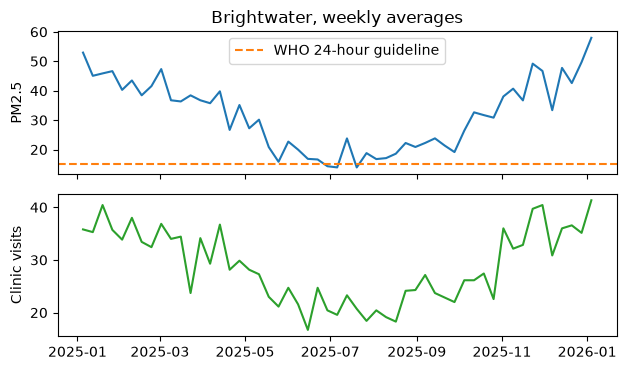

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

air = pd.read_csv("../data/air_quality.csv", parse_dates=["date"])
visits = pd.read_csv("../data/clinic_visits.csv", parse_dates=["date"])
df = air.merge(visits, on=["date", "city"]).query("city == 'Brightwater'")
weekly = df.set_index("date")[["pm25", "visits"]].resample("W").mean()

fig, (top, bottom) = plt.subplots(2, 1, figsize=(6.4, 3.8), sharex=True)
top.plot(weekly.index, weekly["pm25"])
top.axhline(15, color="C1", linestyle="--", label="WHO 24-hour guideline")
top.set_ylabel("PM2.5")
top.set_title("Brightwater, weekly averages")
top.legend()
bottom.plot(weekly.index, weekly["visits"], color="C2")
bottom.set_ylabel("Clinic visits")
fig.tight_layout()
fig.savefig("health_chart.png")
print("Saved health_chart.png")